
---
date: "2026-10-25"
date-modified: last-modified
format:
  html:
    toc: true
---


# The Simplex Method: Tableaux and Pivoting

**Prerequisites:** [Basic Feasible Solutions](basic-feasible-solutions.ipynb) · [The Equational Form of a Linear Program](equational-form.ipynb)

The LP is in equational form, maximize $c^{\mathsf T}x$ subject to $Ax = b$, $x \ge 0$, with $A \in \mathbb{R}^{m\times n}$ and $\operatorname{rank} A = m$. A basis $B$ is **feasible** if its basic solution $x_B = A_B^{-1}b$, $x_N = 0$ is feasible, i.e. $A_B^{-1}b \ge 0$; by [this theorem](basic-feasible-solutions.ipynb#thm-bfs-vertex) these solutions are the vertices of the feasible set $P$. The simplex method moves from a feasible basis to a better one until an optimal one is reached or unboundedness is detected.

## 1\. The Simplex Tableau

::: {#thm-tableau}
## Solving for the Basic Variables

Let $B$ be a basis and $N$ its complement. For $x \in \mathbb{R}^n$,
$$
Ax = b \iff x_B = p + Qx_N, \qquad p = A_B^{-1}b,\quad Q = -A_B^{-1}A_N,
$$
and for every such $x$,
$$
c^{\mathsf T}x = z_0 + r^{\mathsf T}x_N, \qquad z_0 = c_B^{\mathsf T}p,\quad r = c_N + Q^{\mathsf T}c_B .
$$
The vector $p$, the matrix $Q$, the number $z_0$ and the vector $r$ are uniquely determined by these properties.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-tableau
$Ax = A_Bx_B + A_Nx_N$, so $Ax = b \iff A_Bx_B = b - A_Nx_N \iff x_B = A_B^{-1}b - A_B^{-1}A_Nx_N$. Substituting, $c^{\mathsf T}x = c_B^{\mathsf T}x_B + c_N^{\mathsf T}x_N = c_B^{\mathsf T}p + (c_B^{\mathsf T}Q + c_N^{\mathsf T})x_N$. For uniqueness: the solutions of $Ax = b$ are obtained by choosing $x_N$ freely, so if also $x_B = p' + Q'x_N$ for all of them, then $x_N = 0$ gives $p' = p$ and $x_N = e_k$ gives the $k$-th columns $Q'_{\cdot k} = Q_{\cdot k}$; the same argument applies to $z_0, r$. $\blacksquare$
:::

::: {#def-simplex-tableau}
## Simplex Tableau

The **simplex tableau** $\mathcal T(B)$ of a basis $B$ is the system
$$
x_B = p + Qx_N, \qquad z = z_0 + r^{\mathsf T}x_N .
$$
It expresses the basic variables and the objective $z = c^{\mathsf T}x$ through the nonbasic variables. If $B$ is feasible ($p \ge 0$), the tableau comes with its BFS: $x_N = 0$, $x_B = p$, with value $z = z_0$. Rows are indexed by $i \in B$ and columns by $j \in N$: $Q = (q_{ij})$.
:::

By @thm-tableau, the tableau is just a rewriting of the constraints $Ax = b$ and of the objective; together with $x \ge 0$ it describes the same LP.

## 2\. A First Example

::: {#exm-simplex-run}
## Four Tableaux

Maximize $x_1 + x_2$ subject to $-x_1 + x_2 \le 1$, $x_1 \le 3$, $x_2 \le 2$, $x_1, x_2 \ge 0$. Adding slacks $x_3, x_4, x_5$:
$$
-x_1 + x_2 + x_3 = 1, \qquad x_1 + x_4 = 3, \qquad x_2 + x_5 = 2, \qquad x \ge 0 .
$$
The slack columns form the identity matrix, so $B = \{3, 4, 5\}$ is a basis, and it is feasible since $b = (1, 3, 2) \ge 0$.

**Tableau 1**, $B = \{3,4,5\}$, BFS $(0, 0, 1, 3, 2)$, $z = 0$:
$$
x_3 = 1 + x_1 - x_2, \qquad x_4 = 3 - x_1, \qquad x_5 = 2 - x_2, \qquad z = x_1 + x_2 .
$$
Both nonbasic variables have positive coefficients in $z$, so increasing either one increases $z$. Increase $x_2$, keeping $x_1 = 0$. Then $x_3 = 1 - x_2 \ge 0$ requires $x_2 \le 1$, the row of $x_4$ gives no bound, and $x_5 = 2 - x_2 \ge 0$ requires $x_2 \le 2$. So $x_2$ can grow to $1$, where $x_3$ becomes $0$: $x_2$ **enters** the basis and $x_3$ **leaves**. Solving the first row for $x_2$, $x_2 = 1 + x_1 - x_3$, and substituting:

**Tableau 2**, $B = \{2,4,5\}$, BFS $(0, 1, 0, 3, 1)$, $z = 1$:
$$
x_2 = 1 + x_1 - x_3, \qquad x_4 = 3 - x_1, \qquad x_5 = 1 - x_1 + x_3, \qquad z = 1 + 2x_1 - x_3 .
$$
Now $x_1$ enters; the bounds are none (row of $x_2$), $3$ (row of $x_4$), $1$ (row of $x_5$); so $x_5$ leaves.

**Tableau 3**, $B = \{1,2,4\}$, BFS $(1, 2, 0, 2, 0)$, $z = 3$:
$$
x_1 = 1 + x_3 - x_5, \qquad x_2 = 2 - x_5, \qquad x_4 = 2 - x_3 + x_5, \qquad z = 3 + x_3 - 2x_5 .
$$
Now $x_3$ enters and $x_4$ leaves (bound $2$).

**Tableau 4**, $B = \{1,2,3\}$, BFS $(3, 2, 2, 0, 0)$, $z = 5$:
$$
x_1 = 3 - x_4, \qquad x_2 = 2 - x_5, \qquad x_3 = 2 - x_4 + x_5, \qquad z = 5 - x_4 - x_5 .
$$
Every feasible $x$ has $x_4, x_5 \ge 0$, so $z = 5 - x_4 - x_5 \le 5$, and the current BFS attains $5$: it is optimal. The optimum of the original problem is $(x_1, x_2) = (3, 2)$.
:::

In the $(x_1, x_2)$-plane the four BFS are the vertices $(0,0) \to (0,1) \to (1,2) \to (3,2)$ of the pentagon $P$, each joined to the next by an edge. Entering $x_1$ first gives the shorter path $(0,0) \to (3,0) \to (3,2)$.

## 3\. The Pivot Step

::: {#thm-pivot-step}
## Optimality, Unboundedness, and Pivoting

Let $B$ be a feasible basis with tableau $x_B = p + Qx_N$, $z = z_0 + r^{\mathsf T}x_N$.

1. **Optimality.** If $r \le 0$, the BFS of $B$ is optimal.
2. **Unboundedness.** If $r_j > 0$ for some $j \in N$ and $q_{ij} \ge 0$ for all $i \in B$, the LP is unbounded.
3. **Pivot.** Let $r_j > 0$ and suppose $q_{ij} < 0$ for some $i$. Let
$$
t^* = \min\Big\{\frac{p_i}{-q_{ij}} : i \in B,\ q_{ij} < 0\Big\},
$$
attained at $i = k$. Then $B' = (B \setminus \{k\}) \cup \{j\}$ is a feasible basis; its BFS is obtained from that of $B$ by raising $x_j$ from $0$ to $t^*$, and its value is $z_0 + r_jt^* \ge z_0$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-pivot-step
For $t \ge 0$ let $x(t)$ have $x_j = t$, the other nonbasic variables $0$, and $x_B = p + tQ_{\cdot j}$. By @thm-tableau, $Ax(t) = b$ and $c^{\mathsf T}x(t) = z_0 + r_jt$.

1. Every feasible $x$ has $x_N \ge 0$, so $c^{\mathsf T}x = z_0 + r^{\mathsf T}x_N \le z_0$, the value of the BFS.
2. Here $x_B(t) = p + tQ_{\cdot j} \ge p \ge 0$, so $x(t)$ is feasible for all $t \ge 0$, and $c^{\mathsf T}x(t) = z_0 + r_jt \to \infty$.
3. *Feasibility.* For $i$ with $q_{ij} \ge 0$, $x_i(t^*) \ge p_i \ge 0$; for $q_{ij} < 0$, $x_i(t^*) = p_i + t^*q_{ij} \ge 0$ because $t^* \le p_i/(-q_{ij})$; and $x_k(t^*) = 0$. So $x(t^*)$ is feasible, with support in $B'$.

*$B'$ is a basis.* By definition of $Q$, $A_B^{-1}A_j = -Q_{\cdot j}$, i.e. $A_j = -\sum_{i \in B} q_{ij}A_i$. The coefficient of $A_k$ is $-q_{kj} > 0$. If $A_j$ were in the span of $\{A_i : i \in B \setminus \{k\}\}$, it would have a second representation in the basis $\{A_i : i \in B\}$ of $\mathbb{R}^m$, with coefficient $0$ at $A_k$; this contradicts uniqueness of coordinates. So $A_j \notin \operatorname{span}\{A_i : i \in B\setminus\{k\}\}$, and the $m$ columns of $B'$ are independent ([this lemma](linear-independence.ipynb#lem-extend-independent)).

*Its BFS.* $x(t^*)$ is feasible and vanishes off $B'$, so it is the BFS of $B'$ ([uniqueness](basic-feasible-solutions.ipynb#prp-bfs-unique)), with value $z_0 + r_jt^* \ge z_0$. $\blacksquare$
:::

The new tableau $\mathcal T(B')$ is obtained by solving the row of $x_k$ for $x_j$ (possible since $q_{kj} \ne 0$) and substituting into the other rows and into $z$; by the uniqueness in @thm-tableau this gives $\mathcal T(B')$. The rule for $t^*$ is the **ratio test**: $x_j$ is raised as far as the basic variables stay nonnegative. Geometrically the method walks from a vertex along an edge of $P$ (the points $x(t)$, $0 \le t \le t^*$) to a neighbouring vertex.

::: {#def-degenerate-pivot}
## Degenerate Pivot

A pivot with $t^* = 0$ is **degenerate**: it happens when some $p_i = 0$ with $q_{ij} < 0$. The basis changes but the BFS and the value $z$ do not.
:::

::: {#prp-simplex-terminates-nondegenerate}
## Termination Without Degenerate Pivots

If, starting from a feasible basis, pivots according to @thm-pivot-step are performed and none of them is degenerate, then after at most $\binom nm$ pivots the method stops with an optimal BFS or a proof of unboundedness.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-simplex-terminates-nondegenerate
A nondegenerate pivot has $t^* > 0$ and $r_j > 0$, so $z$ increases strictly. The value $z_0$ is determined by the basis, so no basis can occur twice. There are at most $\binom nm$ bases, so pivots can be performed only finitely often; when none is possible, case 1 or case 2 of @thm-pivot-step applies. $\blacksquare$
:::

entering x2 first (as in the example):
B = [3, 4, 5]: x3 = 1 + x1 - x2; x4 = 3 - x1; x5 = 2 - x2 ; z = 0 + x1 + x2
  x2 enters, x3 leaves, step t* = 1
B = [2, 4, 5]: x2 = 1 + x1 - x3; x4 = 3 - x1; x5 = 1 - x1 + x3 ; z = 1 + 2x1 - x3
  x1 enters, x5 leaves, step t* = 1
B = [2, 4, 1]: x2 = 2 - x5; x4 = 2 - x3 + x5; x1 = 1 + x3 - x5 ; z = 3 + x3 - 2x5
  x3 enters, x4 leaves, step t* = 2
B = [2, 3, 1]: x2 = 2 - x5; x3 = 2 - x4 + x5; x1 = 3 - x4 ; z = 5 - x4 - x5
  optimal, value 5

entering x1 first:
B = [3, 4, 5]: x3 = 1 + x1 - x2; x4 = 3 - x1; x5 = 2 - x2 ; z = 0 + x1 + x2
  x1 enters, x4 leaves, step t* = 3
B = [3, 1, 5]: x3 = 4 - x2 - x4; x1 = 3 - x4; x5 = 2 - x2 ; z = 3 + x2 - x4
  x2 enters, x5 leaves, step t* = 2
B = [3, 1, 2]: x3 = 2 - x4 + x5; x1 = 3 - x4; x2 = 2 - x5 ; z = 5 - x4 - x5
  optimal, value 5


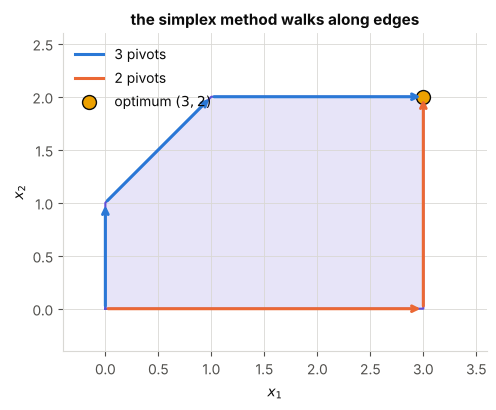

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#d9d8d4", "#a3a29a"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from fractions import Fraction as Fr

def inverse(M):
    """Exact Gauss-Jordan inverse of a square matrix of Fractions."""
    k = len(M); T = [row[:] + [Fr(int(i == j)) for j in range(k)] for i, row in enumerate(M)]
    for col in range(k):
        piv = next(r for r in range(col, k) if T[r][col] != 0)
        T[col], T[piv] = T[piv], T[col]
        T[col] = [v / T[col][col] for v in T[col]]
        for r in range(k):
            if r != col and T[r][col] != 0:
                T[r] = [a - T[r][col] * b_ for a, b_ in zip(T[r], T[col])]
    return [row[k:] for row in T]

def tableau(A, b, c, B):
    m, n = len(A), len(A[0]); N = [j for j in range(n) if j not in B]
    inv = inverse([[Fr(A[i][j]) for j in B] for i in range(m)])
    p = [sum(inv[i][l] * b[l] for l in range(m)) for i in range(m)]
    Q = [[-sum(inv[i][l] * A[l][j] for l in range(m)) for j in N] for i in range(m)]
    z0 = sum(c[B[i]] * p[i] for i in range(m))
    r = [c[N[t]] + sum(Q[i][t] * c[B[i]] for i in range(m)) for t in range(len(N))]
    return N, p, Q, z0, r

def fmt(coef, var):
    return "".join(f" {'+' if v > 0 else '-'} {'' if abs(v) == 1 else abs(v)}x{var[t] + 1}" for t, v in enumerate(coef) if v != 0)

def simplex(A, b, c, B, enter=None, verbose=True):
    """Pivot from feasible basis B. enter: optional list of entering variables (0-based) to follow."""
    B = list(B); path = []; step = 0
    while True:
        N, p, Q, z0, r = tableau(A, b, c, B)
        x = [Fr(0)] * len(c)
        for i, j in enumerate(B): x[j] = p[i]
        path.append(x)
        if verbose:
            print(f"B = {[j + 1 for j in B]}:", "; ".join(f"x{B[i] + 1} = {p[i]}{fmt(Q[i], N)}" for i in range(len(B))),
                  f"; z = {z0}{fmt(r, N)}")
        pos = [t for t in range(len(N)) if r[t] > 0]
        if not pos:
            if verbose: print("  optimal, value", z0)
            return "optimal", path
        t = N.index(enter[step]) if enter and step < len(enter) else pos[0]
        rows = [i for i in range(len(B)) if Q[i][t] < 0]
        if not rows:
            if verbose: print(f"  x{N[t] + 1} can grow without bound: unbounded")
            return "unbounded", path
        k = min(rows, key=lambda i: p[i] / -Q[i][t])
        if verbose: print(f"  x{N[t] + 1} enters, x{B[k] + 1} leaves, step t* = {p[k] / -Q[k][t]}")
        B[k] = N[t]; step += 1

A = [[-1, 1, 1, 0, 0], [1, 0, 0, 1, 0], [0, 1, 0, 0, 1]]; b = [1, 3, 2]; c = [1, 1, 0, 0, 0]
print("entering x2 first (as in the example):")
_, path1 = simplex(A, b, c, [2, 3, 4], enter=[1, 0, 2])
print("\nentering x1 first:")
_, path2 = simplex(A, b, c, [2, 3, 4], enter=[0])

P = np.array([[0, 0], [3, 0], [3, 2], [1, 2], [0, 1]])
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.fill(*P.T, color=VIOLET, alpha=0.15); ax.plot(*np.vstack([P, P[:1]]).T, color=VIOLET)
for path, col, lab, off in [(path1, BLUE, "3 pivots", 0.0), (path2, ORANGE, "2 pivots", 0.0)]:
    pts = np.array([[float(x[0]), float(x[1])] for x in path])
    for a_, b_ in zip(pts[:-1], pts[1:]):
        ax.annotate("", xy=b_, xytext=a_, arrowprops=dict(arrowstyle="->", color=col, lw=2.2))
    ax.plot([], [], color=col, lw=2.2, label=lab)
ax.plot(3, 2, "o", color=YELLOW, mec=INK, ms=10, label="optimum $(3,2)$")
ax.set_aspect("equal"); ax.set_xlim(-0.4, 3.6); ax.set_ylim(-0.4, 2.6); ax.legend(loc="upper left")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("the simplex method walks along edges")
plt.tight_layout(); plt.show()


## 4\. Unboundedness and Degeneracy

::: {#exm-simplex-unbounded}
## An Unbounded LP

Maximize $x_1$ subject to $x_1 - x_2 \le 1$, $-x_1 + x_2 \le 1$, $x \ge 0$. With slacks $x_3, x_4$:
$$
x_3 = 1 - x_1 + x_2, \quad x_4 = 1 + x_1 - x_2, \quad z = x_1 .
$$
$x_1$ enters and $x_3$ leaves (the row of $x_4$ gives no bound):
$$
x_1 = 1 + x_2 - x_3, \quad x_4 = 2 - x_3, \quad z = 1 + x_2 - x_3 .
$$
Now $x_2$ has coefficient $1 > 0$ in $z$ and no negative coefficient in any row, so by @thm-pivot-step(2) the LP is unbounded: $x_2 = t$, $x_3 = 0$, $x_1 = 1 + t$, $x_4 = 2$ is feasible for all $t \ge 0$ with $z = 1 + t$. The feasible set is the strip between two parallel lines, and the method moves from $(0,0)$ to $(1,0)$ and then along the unbounded edge.
:::

::: {#exm-simplex-degenerate}
## A Degenerate Pivot

Maximize $x_2$ subject to $-x_1 + x_2 \le 0$, $x_1 \le 2$, $x \ge 0$:
$$
x_3 = x_1 - x_2, \quad x_4 = 2 - x_1, \quad z = x_2 .
$$
$x_2$ enters, but the row of $x_3$ (with $p = 0$) allows no increase: $t^* = 0$. The pivot still changes the basis, $x_3$ leaving:
$$
x_2 = x_1 - x_3, \quad x_4 = 2 - x_1, \quad z = x_1 - x_3 ,
$$
the same BFS $(0,0,0,2)$ with $z = 0$. Now $x_1$ can enter ($x_4$ leaves at $t^* = 2$):
$$
x_1 = 2 - x_4, \quad x_2 = 2 - x_3 - x_4, \quad z = 2 - x_3 - x_4,
$$
which is optimal: $(x_1, x_2) = (2, 2)$, $z = 2$. Three boundary lines, $x_2 = x_1$, $x_1 = 0$ and $x_2 = 0$, pass through the vertex $(0,0)$, one more than needed in the plane; this is why it has more than one basis.
:::

::: {.callout-warning}
## Cycling
With degenerate pivots $z$ does not increase, and a sequence of degenerate pivots could return to a basis met before; the method would then repeat forever (**cycling**). @prp-simplex-terminates-nondegenerate excludes this only when no degenerate pivot occurs. A suitable rule for choosing the entering and leaving variables avoids cycling; such rules are not treated in this note.
:::

In [2]:

print("unbounded example:")
simplex([[1, -1, 1, 0], [-1, 1, 0, 1]], [1, 1], [1, 0, 0, 0], [2, 3])
print("\ndegenerate example:")
simplex([[-1, 1, 1, 0], [1, 0, 0, 1]], [0, 2], [0, 1, 0, 0], [2, 3]);

unbounded example:
B = [3, 4]: x3 = 1 - x1 + x2; x4 = 1 + x1 - x2 ; z = 0 + x1
  x1 enters, x3 leaves, step t* = 1
B = [1, 4]: x1 = 1 + x2 - x3; x4 = 2 - x3 ; z = 1 + x2 - x3
  x2 can grow without bound: unbounded

degenerate example:
B = [3, 4]: x3 = 0 + x1 - x2; x4 = 2 - x1 ; z = 0 + x2
  x2 enters, x3 leaves, step t* = 0
B = [2, 4]: x2 = 0 + x1 - x3; x4 = 2 - x1 ; z = 0 + x1 - x3
  x1 enters, x4 leaves, step t* = 2
B = [2, 1]: x2 = 2 - x3 - x4; x1 = 2 - x4 ; z = 2 - x3 - x4
  optimal, value 2



## 5\. Finding a First Feasible Basis

If the LP came from $Ax \le b$, $x \ge 0$ with $b \ge 0$, the slack variables form a feasible basis, as in @exm-simplex-run. In general a feasible basis is not apparent; finding one is as hard as deciding feasibility. Multiplying equations by $-1$ we may assume $b \ge 0$.

::: {#thm-phase-one}
## The Auxiliary Problem

Let $b \ge 0$. Introduce new variables $s_1, \dots, s_m$ and consider
$$
(\mathrm{Aux}) \qquad \text{maximize } -(s_1 + \dots + s_m) \quad \text{subject to } Ax + s = b,\quad x, s \ge 0 .
$$

1. The columns of $s$ form a feasible basis of (Aux), with BFS $(x, s) = (0, b)$.
2. (Aux) has an optimal BFS, and its optimal value is $\le 0$.
3. The original LP is feasible if and only if the optimal value of (Aux) is $0$.
4. If $(x^*, s^*)$ is an optimal BFS of (Aux) with value $0$, then $s^* = 0$ and $x^*$ is a BFS of the original LP.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-phase-one

1. The matrix of (Aux) is $(A \mid I)$, of rank $m$; the columns of $I$ are independent and the corresponding basic solution is $s = b \ge 0$, $x = 0$.
2. The objective is $\le 0$ on the feasible set, which is nonempty by 1; apply [the theorem on optimal BFS](basic-feasible-solutions.ipynb#thm-optimal-bfs).
3. If $Ax = b$, $x \ge 0$, then $(x, 0)$ is feasible for (Aux) with value $0$, the largest possible. Conversely, value $0$ with $s \ge 0$ means $s = 0$, so $Ax = b$, $x \ge 0$.
4. Value $0$ gives $s^* = 0$, and $x^*$ is feasible by 3. The support of $(x^*, 0)$ lies among the $x$-columns, and these columns of $(A \mid I)$ are the corresponding columns of $A$; they are independent because $(x^*, 0)$ is a BFS ([support criterion](basic-feasible-solutions.ipynb#prp-bfs-support)). By the same criterion, $x^*$ is a BFS of the original LP. $\blacksquare$
:::

A feasible basis for $x^*$ is then obtained by extending its support to $m$ independent columns of $A$, as in the proof of the [support criterion](basic-feasible-solutions.ipynb#prp-bfs-support). Solving (Aux) is **phase I**; optimizing the original objective from the basis found is **phase II**.

::: {#exm-phase-one}
## Phase I and Phase II

Maximize $x_1 + 2x_2$ subject to $x_1 + 3x_2 + x_3 = 4$, $2x_2 + x_3 = 2$, $x \ge 0$. With auxiliary variables $x_4, x_5$, (Aux) maximizes $w = -x_4 - x_5$:
$$
x_4 = 4 - x_1 - 3x_2 - x_3, \quad x_5 = 2 - 2x_2 - x_3, \quad w = -6 + x_1 + 5x_2 + 2x_3 .
$$
Pivoting ($x_1$ enters, $x_4$ leaves; then $x_2$ enters, $x_5$ leaves) gives
$$
x_1 = 1 + \tfrac12x_3 - x_4 + \tfrac32x_5, \quad x_2 = 1 - \tfrac12x_3 - \tfrac12x_5, \quad w = -x_4 - x_5,
$$
optimal with $w = 0$. So $B = \{1, 2\}$ is a feasible basis of the original LP, with BFS $(1, 1, 0)$. Deleting $x_4, x_5$ and writing $z = x_1 + 2x_2 = 3 - \frac12x_3$ gives its tableau, which is already optimal: the optimum is $z = 3$ at $(1, 1, 0)$.
:::

In [3]:

print("phase I:")
simplex([[1, 3, 1, 1, 0], [0, 2, 1, 0, 1]], [4, 2], [0, 0, 0, -1, -1], [3, 4])
print("\nphase II from B = {1, 2}:")
simplex([[1, 3, 1], [0, 2, 1]], [4, 2], [1, 2, 0], [0, 1]);

phase I:
B = [4, 5]: x4 = 4 - x1 - 3x2 - x3; x5 = 2 - 2x2 - x3 ; z = -6 + x1 + 5x2 + 2x3
  x1 enters, x4 leaves, step t* = 4
B = [1, 5]: x1 = 4 - 3x2 - x3 - x4; x5 = 2 - 2x2 - x3 ; z = -2 + 2x2 + x3 - x4
  x2 enters, x5 leaves, step t* = 1
B = [1, 2]: x1 = 1 + 1/2x3 - x4 + 3/2x5; x2 = 1 - 1/2x3 - 1/2x5 ; z = 0 - x4 - x5
  optimal, value 0

phase II from B = {1, 2}:
B = [1, 2]: x1 = 1 + 1/2x3; x2 = 1 - 1/2x3 ; z = 3 - 1/2x3
  optimal, value 3



## 6\. The Method and Its Open Questions

::: {#def-simplex-method}
## The Simplex Method

1. Bring the LP to equational form with $\operatorname{rank} A = m$ and $b \ge 0$; find a feasible basis by phase I (or stop: infeasible).
2. Compute the tableau of the current basis $B$. If $r \le 0$, stop: the BFS is optimal.
3. Choose $j \in N$ with $r_j > 0$. If $q_{ij} \ge 0$ for all $i$, stop: the LP is unbounded.
4. Otherwise choose $k$ by the ratio test, replace $B$ by $(B \setminus \{k\}) \cup \{j\}$, and go to 2.
:::

Correctness of each stop is @thm-pivot-step. Three questions are left open here:

- **Pivot rules.** Which $j$ to choose when several $r_j > 0$, and which $k$ when the ratio test has ties. @exm-simplex-run shows that the choice affects the number of steps.
- **Cycling.** Whether the method always stops when degenerate pivots occur (see the warning above).
- **Running time.** The number of pivots. For the usual pivot rules there are LPs on which the method visits exponentially many vertices, although in practice it typically needs few pivots.